TensorFlow version: 2.21.0
GPU available: False
228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

Dataset path: /root/.keras/datasets/flower_photos/flower_photos
Total images: 3670
Number of classes: 5

Training images: 2569
Validation images: 550
Test images: 551

Training class counts: [443 629 449 489 559]
Validation class counts: [ 95 134  96 105 120]
Test class counts: [ 95 135  96 105 120]


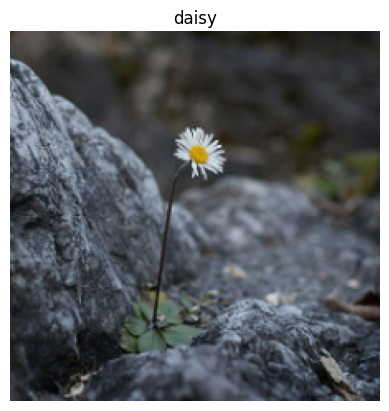

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 119s 1s/step - accuracy: 0.7373 - loss: 0.7421 - val_accuracy: 0.8364 - val_loss: 0.4856
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 99s 1s/step - accuracy: 0.8805 - loss: 0.3658 - val_accuracy: 0.8582 - val_loss: 0.4199
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.9042 - loss: 0.2887 - val_accuracy: 0.8764 - val_loss: 0.3826
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 93s 1s/step - accuracy: 0.9241 - loss: 0.2391 - val_accuracy: 0.8745 - val_loss: 0.3831
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 140s 1s/step - accuracy: 0.9362 - loss: 0.2088 - val_accuracy: 0.8782 - val_loss: 0.3670


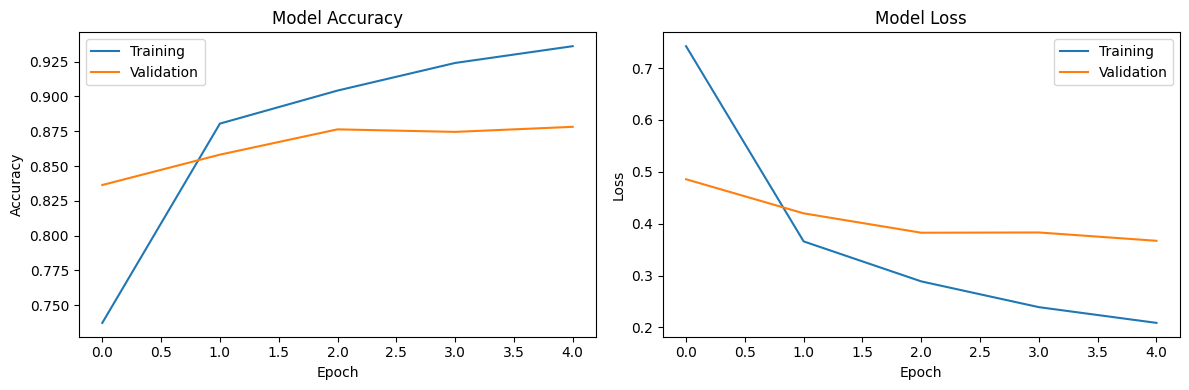

18/18 ━━━━━━━━━━━━━━━━━━━━ 16s 900ms/step - accuracy: 0.8875 - loss: 0.3160

Test loss: 0.3160
Test accuracy: 88.75%
18/18 ━━━━━━━━━━━━━━━━━━━━ 18s 965ms/step

True label counts:
[ 95 135  96 105 120]

Confusion matrix:
[[ 87   4   2   0   2]
 [  1 129   0   5   0]
 [  3   0  80   1  12]
 [  3   6   3  86   7]
 [  4   2   5   2 107]]

Classification report:
              precision    recall  f1-score   support

       daisy       0.89      0.92      0.90        95
   dandelion       0.91      0.96      0.93       135
       roses       0.89      0.83      0.86        96
  sunflowers       0.91      0.82      0.86       105
      tulips       0.84      0.89      0.86       120

    accuracy                           0.89       551
   macro avg       0.89      0.88      0.88       551
weighted avg       0.89      0.89      0.89       551



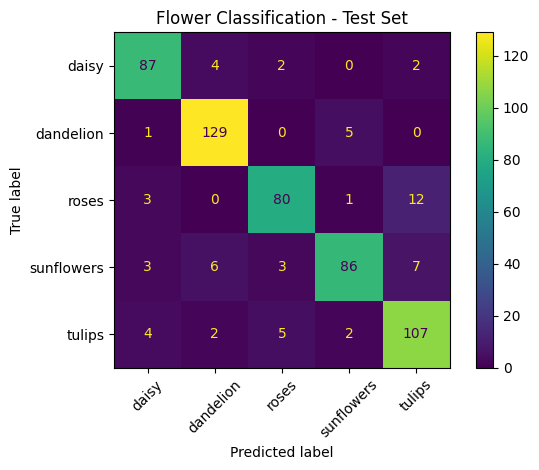


Model saved as flower_classifier.keras
Model reloaded successfully.
Output shape: (None, 5)


KeyboardInterrupt: 

In [1]:

# ============================================================
# PROJECT 5: FLOWER CLASSIFICATION USING MOBILENETV2
# Dataset: 3,670 flower images, 5 classes
# Split: 70% training / 15% validation / 15% testing
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42
EPOCHS = 5

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

# ------------------------------------------------------------
# 2. DOWNLOAD DATASET
# ------------------------------------------------------------

dataset_url = (
    "https://storage.googleapis.com/"
    "download.tensorflow.org/example_images/flower_photos.tgz"
)

archive_path = tf.keras.utils.get_file(
    "flower_photos",
    origin=dataset_url,
    untar=True
)

dataset_path = os.path.join(archive_path, "flower_photos")

class_names = [
    "daisy",
    "dandelion",
    "roses",
    "sunflowers",
    "tulips"
]

print("\nDataset path:", dataset_path)

# ------------------------------------------------------------
# 3. COLLECT IMAGE PATHS AND LABELS
# ------------------------------------------------------------

image_paths = []
image_labels = []

for label, class_name in enumerate(class_names):
    class_folder = os.path.join(dataset_path, class_name)

    for filename in os.listdir(class_folder):
        file_path = os.path.join(class_folder, filename)

        if os.path.isfile(file_path):
            image_paths.append(file_path)
            image_labels.append(label)

image_paths = np.array(image_paths)
image_labels = np.array(image_labels)

print("Total images:", len(image_paths))
print("Number of classes:", len(class_names))

# ------------------------------------------------------------
# 4. SPLIT INTO TRAIN / VALIDATION / TEST
# ------------------------------------------------------------

# First: 70% training, 30% temporary holdout.
# Stratification preserves class proportions in each split.

X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    image_labels,
    test_size=0.30,
    random_state=SEED,
    stratify=image_labels
)

# Second: divide the remaining 30% equally into validation/test.
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("\nTraining images:", len(X_train))
print("Validation images:", len(X_val))
print("Test images:", len(X_test))

print("\nTraining class counts:",
      np.bincount(y_train, minlength=len(class_names)))
print("Validation class counts:",
      np.bincount(y_val, minlength=len(class_names)))
print("Test class counts:",
      np.bincount(y_test, minlength=len(class_names)))

# ------------------------------------------------------------
# 5. LOAD AND PREPROCESS IMAGES
# ------------------------------------------------------------

def load_image(path, label):
    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)

    return image, label


def make_dataset(paths, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            len(paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

# Display one training image.
for image_batch, label_batch in train_ds.take(1):
    display_image = (image_batch[0].numpy() + 1.0) / 2.0

    plt.imshow(np.clip(display_image, 0, 1))
    plt.title(class_names[int(label_batch[0].numpy())])
    plt.axis("off")
    plt.show()

# ------------------------------------------------------------
# 6. BUILD MOBILENETV2 TRANSFER-LEARNING MODEL
# ------------------------------------------------------------

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained feature extractor.
base_model.trainable = False

model = tf.keras.Sequential([
    tf.keras.Input(shape=(224, 224, 3)),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(len(class_names), activation="softmax")
])

model.summary()

# ------------------------------------------------------------
# 7. COMPILE MODEL
# ------------------------------------------------------------

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ------------------------------------------------------------
# 8. TRAIN MODEL
# ------------------------------------------------------------

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

# ------------------------------------------------------------
# 9. PLOT ACCURACY AND LOSS
# ------------------------------------------------------------

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. EVALUATE ON THE HELD-OUT TEST SET
# ------------------------------------------------------------

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"\nTest loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

# ------------------------------------------------------------
# 11. CONFUSION MATRIX AND CLASSIFICATION REPORT
# ------------------------------------------------------------

y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# y_test contains the true labels in the same order as X_test.
y_true = y_test

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)

print("\nTrue label counts:")
print(np.bincount(y_true, minlength=len(class_names)))

print("\nConfusion matrix:")
print(cm)

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(xticks_rotation=45)
plt.title("Flower Classification - Test Set")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. SAVE MODEL
# ------------------------------------------------------------

model.save("flower_classifier.keras")
print("\nModel saved as flower_classifier.keras")

# ------------------------------------------------------------
# 13. RELOAD AND VERIFY MODEL
# ------------------------------------------------------------

loaded_model = tf.keras.models.load_model("flower_classifier.keras")

print("Model reloaded successfully.")
print("Output shape:", loaded_model.output_shape)

# ------------------------------------------------------------
# 14. PREDICT A NEW FLOWER IMAGE
# ------------------------------------------------------------

# In Google Colab, upload a flower image when prompted.
try:
    from google.colab import files

    uploaded = files.upload()

    if uploaded:
        new_image_path = next(iter(uploaded))

        image = tf.keras.utils.load_img(
            new_image_path,
            target_size=IMAGE_SIZE
        )

        image_array = tf.keras.utils.img_to_array(image)
        image_array = np.expand_dims(image_array, axis=0)

        # Apply the same preprocessing used during training.
        image_array = tf.keras.applications.mobilenet_v2.preprocess_input(
            image_array
        )

        probabilities = loaded_model.predict(
            image_array,
            verbose=0
        )[0]

        predicted_index = int(np.argmax(probabilities))

        print("\nPredicted flower:", class_names[predicted_index])
        print(f"Confidence: {probabilities[predicted_index] * 100:.2f}%")

        plt.imshow(image)
        plt.title(
            f"{class_names[predicted_index]} "
            f"({probabilities[predicted_index] * 100:.1f}%)"
        )
        plt.axis("off")
        plt.show()

except ImportError:
    print(
        "\nPrediction upload is available in Google Colab. "
        "Run the prediction section there."
    )

print("\nPROJECT PIPELINE FINISHED")


In [2]:
model.save("flower_classifier.keras")
loaded_model = tf.keras.models.load_model("flower_classifier.keras")

In [6]:
from google.colab import files

uploaded = files.upload()

Saving premium_photo-1673716788461-0aa43e5d2015.avif to premium_photo-1673716788461-0aa43e5d2015.avif


Predicted flower: roses
Confidence: 81.89%


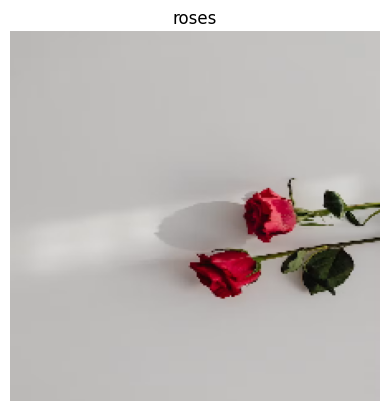

In [7]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

class_names = [
    "daisy",
    "dandelion",
    "roses",
    "sunflowers",
    "tulips"
]

image_path = next(iter(uploaded))

img = tf.keras.utils.load_img(
    image_path,
    target_size=(224, 224)
)

img_array = tf.keras.utils.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

img_array = tf.keras.applications.mobilenet_v2.preprocess_input(
    img_array
)

probabilities = loaded_model.predict(img_array, verbose=0)[0]
predicted_index = np.argmax(probabilities)

print("Predicted flower:", class_names[predicted_index])
print(f"Confidence: {probabilities[predicted_index] * 100:.2f}%")

plt.imshow(img)
plt.title(class_names[predicted_index])
plt.axis("off")
plt.show()